# EV Charging Demand Prediction

## Machine Learning Project

### Objective

The objective of this project is to predict the hourly electricity
demand of EV charging stations using historical charging demand,
station characteristics, calendar information, and weather conditions.

### Business Problem

Electric vehicle charging stations experience different levels of
electricity demand throughout the day. Accurate demand prediction can
help charging station operators plan charger availability, manage
electricity consumption, and reduce peak-load problems.

### Machine Learning Type

Supervised Learning - Regression

### Target Variable

`energy_consumed_kwh`

### Models

- Linear Regression
- Random Forest Regressor
- Gradient Boosting Regressor
- XGBoost Regressor

### Evaluation Metrics

- MAE
- RMSE
- R² Score

## Project Workflow

The complete machine learning workflow followed in this project is:

1. Define the business problem
2. Load and understand the dataset
3. Perform data quality checks
4. Conduct exploratory data analysis (EDA)
5. Engineer time-based features
6. Select prediction features
7. Perform chronological train-validation-test splitting
8. Preprocess categorical and numerical features
9. Train multiple regression models
10. Evaluate models using MAE, RMSE, and R²
11. Compare model performance
12. Select the best-performing model
13. Analyze feature importance
14. Evaluate the final model on unseen test data
15. Save the trained model for deployment

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the prepared ML dataset

df = pd.read_csv("../data/ev_charging_ml.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (191424, 18)


## Dataset Overview

The dataset contains hourly observations from multiple EV charging
stations.

### Dataset Characteristics

- **Rows:** 191,424
- **Columns:** 18
- **Time period:** January 2024 – September 2026
- **Stations:** 8
- **Prediction target:** `energy_consumed_kwh`
- **Problem type:** Regression
- **Missing values:** None

### Main Feature Groups

**Station Features**
- Station ID
- Location
- Charger count

**Time Features**
- Hour
- Day of week
- Month
- Weekend indicator
- Holiday indicator

**Weather Features**
- Temperature
- Humidity
- Rainfall

**Historical Demand Features**
- Previous hour demand
- Previous day demand
- Previous week demand
- 24-hour rolling mean
- 7-day rolling mean

In [4]:
df.head()

,timestamp,station_id,location,charger_count,hour,day_of_week,month,is_weekend,is_holiday,temperature,humidity,rainfall,previous_hour_demand,previous_day_demand,previous_week_demand,rolling_24h_mean,rolling_7d_mean,energy_consumed_kwh
0,2024-01-08 00:00:00,ST001,Kochi,8,0,0,1,0,0,23.6,73.5,0.00,109.19,13.76,13.51,72.592917,64.555536,12.91
1,2024-01-08 00:00:00,ST002,Trivandrum,12,0,0,1,0,0,24.8,85.5,0.09,87.85,24.46,87.25,100.812917,96.402917,39.89
2,2024-01-08 00:00:00,ST003,Kottayam,10,0,0,1,0,0,24.1,71.2,0.14,101.46,0.00,20.70,78.264167,78.018988,54.38
3,2024-01-08 00:00:00,ST004,Kozhikode,15,0,0,1,0,0,24.2,71.7,0.00,248.76,26.31,35.75,108.523333,119.898214,90.80
4,2024-01-08 00:00:00,ST005,Thrissur,6,0,0,1,0,0,22.8,84.3,0.00,69.22,52.66,40.17,55.495833,43.229167,24.67


In [5]:
# Check column names

print("Columns in the dataset:")
for i, column in enumerate(df.columns, 1):
    print(f"{i}. {column}")

Columns in the dataset:
1. timestamp
2. station_id
3. location
4. charger_count
5. hour
6. day_of_week
7. month
8. is_weekend
9. is_holiday
10. temperature
11. humidity
12. rainfall
13. previous_hour_demand
14. previous_day_demand
15. previous_week_demand
16. rolling_24h_mean
17. rolling_7d_mean
18. energy_consumed_kwh


In [6]:
df.dtypes

timestamp                object
station_id               object
location                 object
charger_count             int64
hour                      int64
day_of_week               int64
month                     int64
is_weekend                int64
is_holiday                int64
temperature             float64
humidity                float64
rainfall                float64
previous_hour_demand    float64
previous_day_demand     float64
previous_week_demand    float64
rolling_24h_mean        float64
rolling_7d_mean         float64
energy_consumed_kwh     float64
dtype: object

In [7]:
df.describe()

,charger_count,hour,day_of_week,month,is_weekend,is_holiday,temperature,humidity,rainfall,previous_hour_demand,previous_day_demand,previous_week_demand,rolling_24h_mean,rolling_7d_mean,energy_consumed_kwh
count,191424.000000,191424.000000,191424.000000,191424.000000,191424.000000,191424.000000,191424.000000,191424.000000,191424.000000,191424.000000,191424.000000,191424.000000,191424.000000,191424.000000,191424.000000
mean,10.375000,11.500000,2.993982,6.147442,0.284855,0.015045,28.310692,74.976462,0.428979,81.607711,81.613981,81.605716,81.609578,81.612631,81.608634
std,2.912803,6.922205,2.000498,3.287828,0.451346,0.121733,2.924500,9.951037,1.227865,67.317551,67.314335,67.336389,24.959538,22.784669,67.318086
min,6.000000,0.000000,0.000000,1.000000,0.000000,0.000000,18.200000,40.000000,0.000000,0.000000,0.000000,0.000000,25.410417,39.106429,0.000000
25%,8.000000,5.750000,1.000000,3.000000,0.000000,0.000000,26.100000,68.200000,0.000000,34.840000,34.850000,34.850000,62.182500,63.468333,34.840000
50%,10.000000,11.500000,3.000000,6.000000,0.000000,0.000000,28.300000,75.000000,0.000000,65.030000,65.045000,65.010000,78.258958,78.714940,65.020000
75%,12.500000,17.250000,5.000000,9.000000,1.000000,0.000000,30.400000,81.700000,0.250000,110.150000,110.160000,110.132500,99.819688,101.289732,110.160000
max,15.000000,23.000000,6.000000,12.000000,1.000000,1.000000,39.000000,100.000000,27.700000,882.410000,882.410000,882.410000,174.808333,131.955476,882.410000


In [8]:
# Check missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
timestamp               0
station_id              0
location                0
charger_count           0
hour                    0
day_of_week             0
month                   0
is_weekend              0
is_holiday              0
temperature             0
humidity                0
rainfall                0
previous_hour_demand    0
previous_day_demand     0
previous_week_demand    0
rolling_24h_mean        0
rolling_7d_mean         0
energy_consumed_kwh     0
dtype: int64


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution
of EV charging demand and identify patterns between demand, time,
station characteristics, and weather conditions.

In [9]:
# Convert timestamp to datetime format

df["timestamp"] = pd.to_datetime(df["timestamp"])

print("Timestamp converted successfully!")
print("Start:", df["timestamp"].min())
print("End:", df["timestamp"].max())

Timestamp converted successfully!


Start: 2024-01-08 00:00:00
End: 2026-09-30 23:00:00


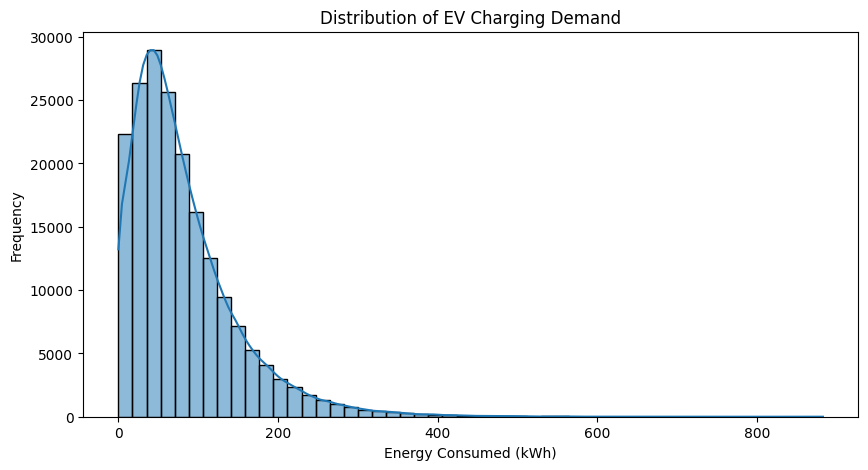

In [10]:
# Distribution of EV charging demand

plt.figure(figsize=(10, 5))

sns.histplot(
    df["energy_consumed_kwh"],
    bins=50,
    kde=True
)

plt.title("Distribution of EV Charging Demand")
plt.xlabel("Energy Consumed (kWh)")
plt.ylabel("Frequency")
plt.show()

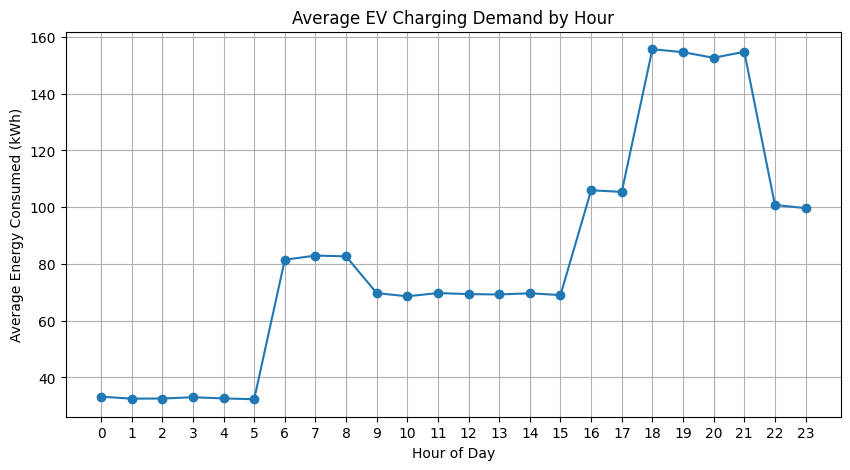

In [11]:
# Average charging demand by hour

hourly_demand = df.groupby("hour")["energy_consumed_kwh"].mean()

plt.figure(figsize=(10, 5))

plt.plot(hourly_demand.index, hourly_demand.values, marker="o")

plt.title("Average EV Charging Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Energy Consumed (kWh)")
plt.xticks(range(24))
plt.grid(True)
plt.show()

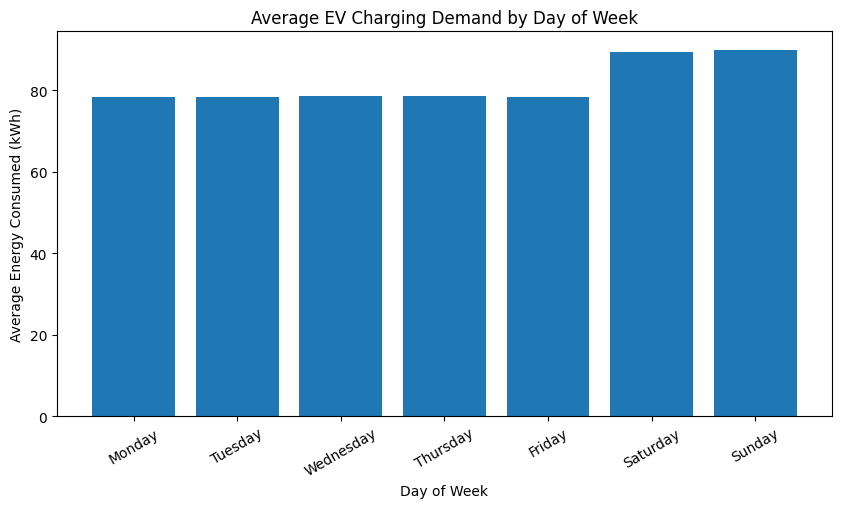

In [12]:
# Average charging demand by day of week

daily_demand = df.groupby("day_of_week")["energy_consumed_kwh"].mean()

day_names = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

plt.figure(figsize=(10, 5))

plt.bar(day_names, daily_demand.values)

plt.title("Average EV Charging Demand by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Energy Consumed (kWh)")
plt.xticks(rotation=30)
plt.show()

In [13]:
# Average charging demand by station

station_demand = (
    df.groupby(["station_id", "location"])["energy_consumed_kwh"]
    .mean()
    .sort_values(ascending=False)
)

station_demand

station_id  location  
ST004       Kozhikode     117.313309
ST007       Alappuzha     109.676719
ST002       Trivandrum     93.987795
ST006       Kannur         79.032513
ST003       Kottayam       78.396569
ST008       Kollam         63.538368
ST001       Kochi          63.010990
ST005       Thrissur       47.912808
Name: energy_consumed_kwh, dtype: float64

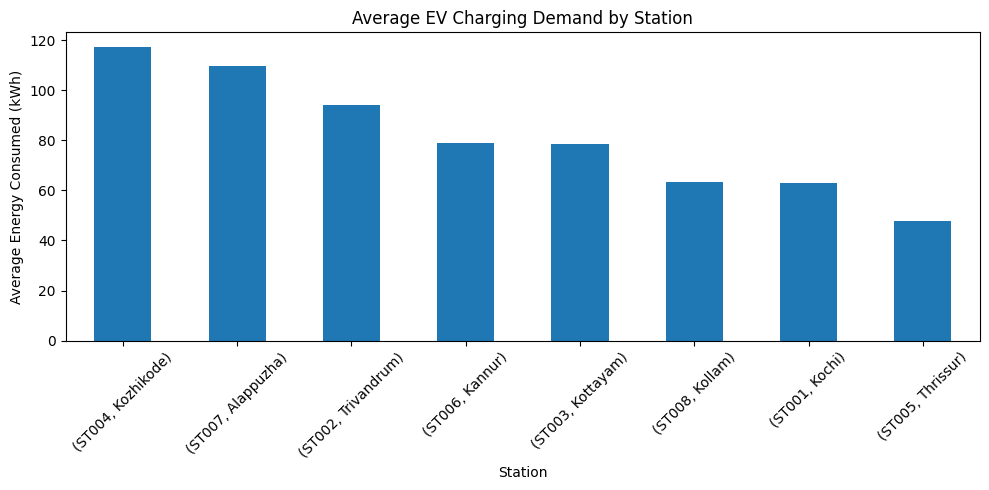

In [14]:
plt.figure(figsize=(10, 5))

station_demand.plot(kind="bar")

plt.title("Average EV Charging Demand by Station")
plt.xlabel("Station")
plt.ylabel("Average Energy Consumed (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

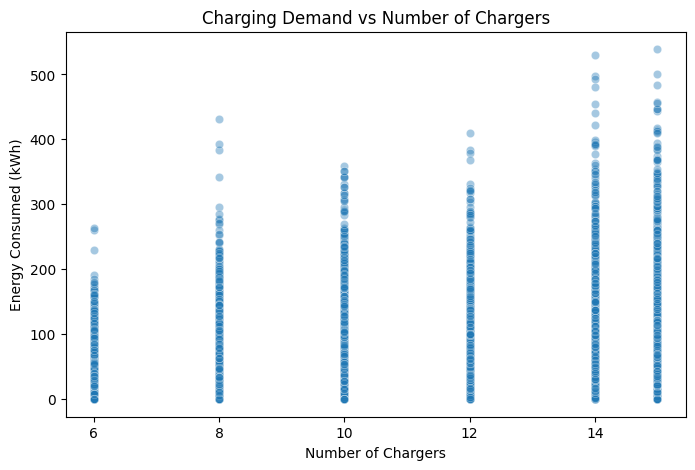

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df.sample(10000, random_state=42),
    x="charger_count",
    y="energy_consumed_kwh",
    alpha=0.4
)

plt.title("Charging Demand vs Number of Chargers")
plt.xlabel("Number of Chargers")
plt.ylabel("Energy Consumed (kWh)")
plt.show()

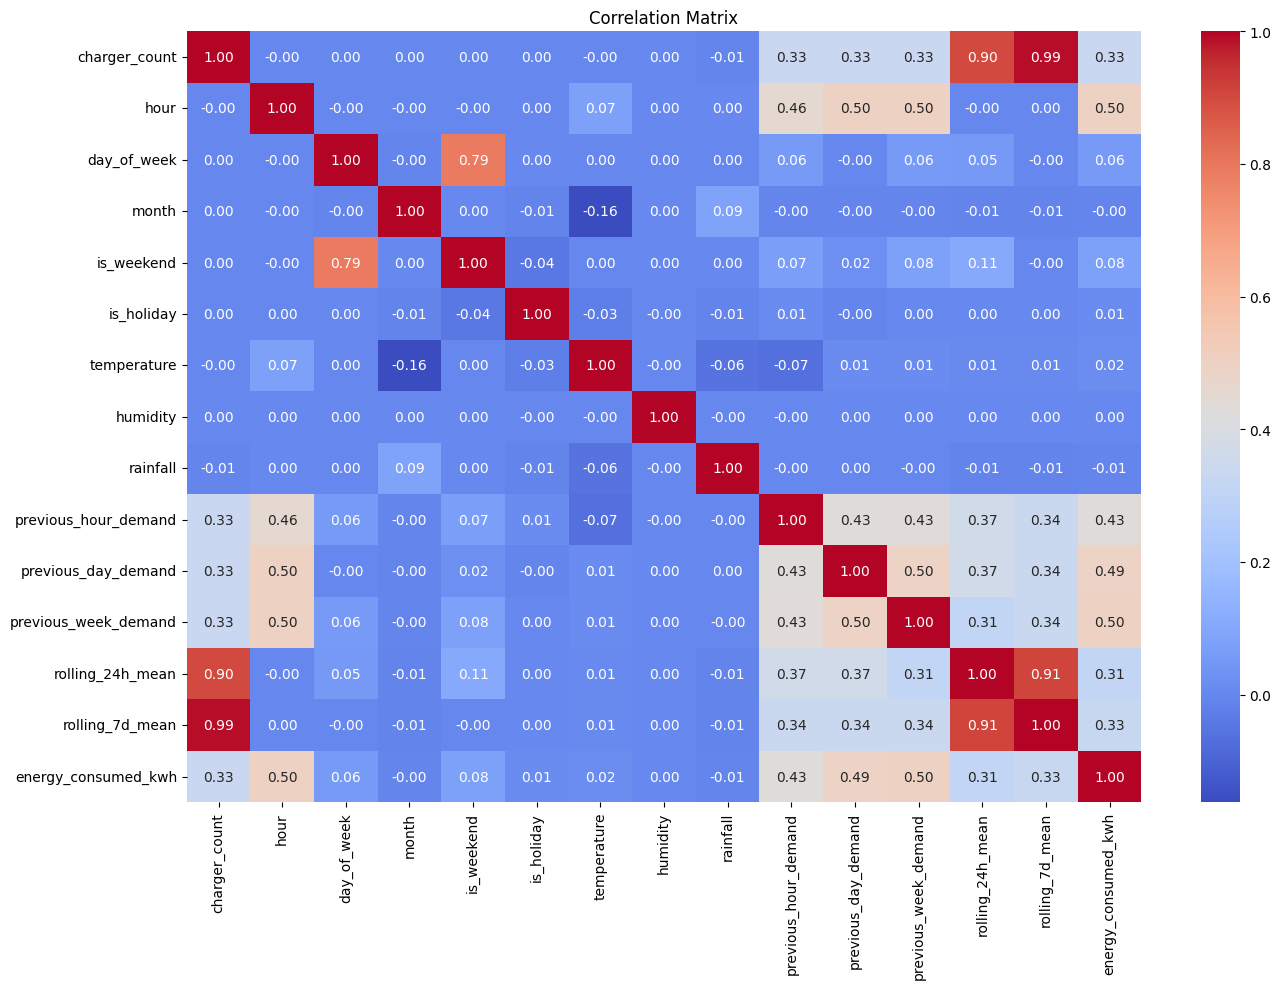

In [16]:
# Correlation matrix

numeric_columns = df.select_dtypes(include=np.number).columns

correlation = df[numeric_columns].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## Feature Engineering

Time-based features are transformed to capture the cyclical nature
of hours and days.

Cyclic encoding allows the model to understand that:

- 23:00 and 00:00 are adjacent
- Sunday and Monday are adjacent

We use sine and cosine transformations for this purpose.m

In [17]:
# Cyclic encoding for hour of day

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

# Cyclic encoding for day of week

df["day_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["day_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

print("Cyclic time features created successfully!")

Cyclic time features created successfully!


In [18]:
# Display the new features

df[
    [
        "hour",
        "hour_sin",
        "hour_cos",
        "day_of_week",
        "day_sin",
        "day_cos"
    ]
].head(10)

,hour,hour_sin,hour_cos,day_of_week,day_sin,day_cos
0,0,0.000000,1.000000,0,0.0,1.0
1,0,0.000000,1.000000,0,0.0,1.0
2,0,0.000000,1.000000,0,0.0,1.0
3,0,0.000000,1.000000,0,0.0,1.0
4,0,0.000000,1.000000,0,0.0,1.0
5,0,0.000000,1.000000,0,0.0,1.0
6,0,0.000000,1.000000,0,0.0,1.0
7,0,0.000000,1.000000,0,0.0,1.0
8,1,0.258819,0.965926,0,0.0,1.0
9,1,0.258819,0.965926,0,0.0,1.0


## Feature Selection

The target variable is `energy_consumed_kwh`.

Current-period charging activity variables are not used as predictors
because they would not be available when making a demand prediction.

Historical demand features are retained because they represent
information available from previous periods.

In [19]:
# Define target variable

target = "energy_consumed_kwh"

# Features used for prediction
features = [
    "station_id",
    "location",
    "charger_count",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "is_holiday",
    "temperature",
    "humidity",
    "rainfall",
    "previous_hour_demand",
    "previous_day_demand",
    "previous_week_demand",
    "rolling_24h_mean",
    "rolling_7d_mean",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos"
]

X = df[features]
y = df[target]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (191424, 20)
Target shape: (191424,)


## Time-Based Data Split

Since EV charging demand is time-dependent, a chronological split is
used instead of a random train-test split.

- Training: January 2024 – December 2025
- Validation: January 2026 – June 2026
- Testing: July 2026 – September 2026

This prevents future information from being used to train the model.m


In [20]:
# Sort data chronologically

df = df.sort_values("timestamp").reset_index(drop=True)

# Define time periods

train_df = df[
    df["timestamp"] < "2026-01-01"
]

validation_df = df[
    (df["timestamp"] >= "2026-01-01") &
    (df["timestamp"] < "2026-07-01")
]

test_df = df[
    df["timestamp"] >= "2026-07-01"
]

print("Training set:", train_df.shape)
print("Validation set:", validation_df.shape)
print("Test set:", test_df.shape)

Training set: (139008, 22)
Validation set: (34752, 22)
Test set: (17664, 22)


In [21]:
# Prepare training data

X_train = train_df[features]
y_train = train_df[target]

# Prepare validation data

X_val = validation_df[features]
y_val = validation_df[target]

# Prepare test data

X_test = test_df[features]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (139008, 20)
X_val: (34752, 20)
X_test: (17664, 20)


## Data Preprocessing

Categorical variables are converted into numerical representations
using One-Hot Encoding.

Numerical features are standardized using StandardScaler.

The preprocessing steps are fitted only on the training data to
avoid data leakage.m

In [22]:
# Identify categorical and numerical features

categorical_features = [
    "station_id",
    "location"
]

numerical_features = [
    "charger_count",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "is_holiday",
    "temperature",
    "humidity",
    "rainfall",
    "previous_hour_demand",
    "previous_day_demand",
    "previous_week_demand",
    "rolling_24h_mean",
    "rolling_7d_mean",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos"
]

print("Categorical features:", categorical_features)
print("Numerical features:", len(numerical_features))

Categorical features: ['station_id', 'location']
Numerical features: 18


In [23]:
# Create preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## Baseline Model — Linear Regression

Linear Regression is used as the baseline model.

The purpose of the baseline is to establish a reference performance
against which more advanced machine learning models can be compared.

In [24]:
# Create Linear Regression pipeline

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

# Train the model

linear_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


In [25]:
# Predictions on validation set

y_val_pred_linear = linear_model.predict(X_val)

print("Predictions generated successfully!")

Predictions generated successfully!


In [26]:
# Evaluate Linear Regression

mae_linear = mean_absolute_error(y_val, y_val_pred_linear)

rmse_linear = np.sqrt(
    mean_squared_error(y_val, y_val_pred_linear)
)

r2_linear = r2_score(
    y_val,
    y_val_pred_linear
)

print("Linear Regression Validation Performance")
print("-----------------------------------------")
print(f"MAE  : {mae_linear:.2f}")
print(f"RMSE : {rmse_linear:.2f}")
print(f"R²   : {r2_linear:.4f}")

Linear Regression Validation Performance
-----------------------------------------
MAE  : 37.23
RMSE : 51.81
R²   : 0.4180


## Random Forest Regressor

Random Forest is an ensemble learning algorithm that combines
multiple decision trees.

It can capture nonlinear relationships between charging demand
and features such as historical demand, charger count, time,
and weather conditions.


In [27]:
# Random Forest model

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=150,
                max_depth=20,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train the model

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [28]:
# Random Forest predictions

y_val_pred_rf = random_forest_model.predict(X_val)

print("Predictions generated successfully!")

Predictions generated successfully!


In [29]:
# Evaluate Random Forest

mae_rf = mean_absolute_error(y_val, y_val_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_val, y_val_pred_rf)
)

r2_rf = r2_score(
    y_val,
    y_val_pred_rf
)

print("Random Forest Validation Performance")
print("------------------------------------")
print(f"MAE  : {mae_rf:.2f}")
print(f"RMSE : {rmse_rf:.2f}")
print(f"R²   : {r2_rf:.4f}")

Random Forest Validation Performance
------------------------------------
MAE  : 34.78
RMSE : 48.66
R²   : 0.4866


## Gradient Boosting Regressor

Gradient Boosting builds decision trees sequentially.

Each new tree attempts to correct the errors made by the previous
trees. This allows the model to capture complex nonlinear relationships
in EV charging demand.m


In [30]:
# Gradient Boosting model

gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=150,
                learning_rate=0.05,
                max_depth=5,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42
            )
        )
    ]
)

# Train the model

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


In [31]:
# Gradient Boosting predictions

y_val_pred_gb = gradient_boosting_model.predict(X_val)

print("Predictions generated successfully!")

Predictions generated successfully!


In [32]:
# Evaluate Gradient Boosting

mae_gb = mean_absolute_error(y_val, y_val_pred_gb)

rmse_gb = np.sqrt(
    mean_squared_error(y_val, y_val_pred_gb)
)

r2_gb = r2_score(
    y_val,
    y_val_pred_gb
)

print("Gradient Boosting Validation Performance")
print("----------------------------------------")
print(f"MAE  : {mae_gb:.2f}")
print(f"RMSE : {rmse_gb:.2f}")
print(f"R²   : {r2_gb:.4f}")

Gradient Boosting Validation Performance
----------------------------------------
MAE  : 34.31
RMSE : 47.99
R²   : 0.5007


## XGBoost Regressor

XGBoost is an optimized gradient boosting algorithm based on decision
trees.

It is widely used for structured/tabular datasets because it can model
nonlinear relationships and interactions between features effectively.

XGBoost will be compared with Linear Regression, Random Forest, and
Gradient Boosting.m

In [33]:
# XGBoost model

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBRegressor(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=6,
                min_child_weight=3,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train the model

xgb_model.fit(X_train, y_train)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [34]:
# XGBoost predictions

y_val_pred_xgb = xgb_model.predict(X_val)

print("Predictions generated successfully!")

Predictions generated successfully!


In [35]:
# Evaluate XGBoost

mae_xgb = mean_absolute_error(y_val, y_val_pred_xgb)

rmse_xgb = np.sqrt(
    mean_squared_error(y_val, y_val_pred_xgb)
)

r2_xgb = r2_score(
    y_val,
    y_val_pred_xgb
)

print("XGBoost Validation Performance")
print("------------------------------")
print(f"MAE  : {mae_xgb:.2f}")
print(f"RMSE : {rmse_xgb:.2f}")
print(f"R²   : {r2_xgb:.4f}")

XGBoost Validation Performance
------------------------------
MAE  : 34.37
RMSE : 48.12
R²   : 0.4980


## Model Comparison

The four regression models are compared using MAE, RMSE, and R² Score.

Lower MAE and RMSE indicate better prediction accuracy, while a higher
R² Score indicates better explanatory performance.

In [36]:
# Create model comparison table

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],
    "MAE": [
        mae_linear,
        mae_rf,
        mae_gb,
        mae_xgb
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf,
        rmse_gb,
        rmse_xgb
    ],
    "R2": [
        r2_linear,
        r2_rf,
        r2_gb,
        r2_xgb
    ]
})

model_comparison = model_comparison.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

model_comparison

,Model,MAE,RMSE,R2
0,Gradient Boosting,34.305811,47.988147,0.500742
1,XGBoost,34.367709,48.120897,0.497976
2,Random Forest,34.779316,48.663290,0.486595
3,Linear Regression,37.232210,51.814296,0.417956


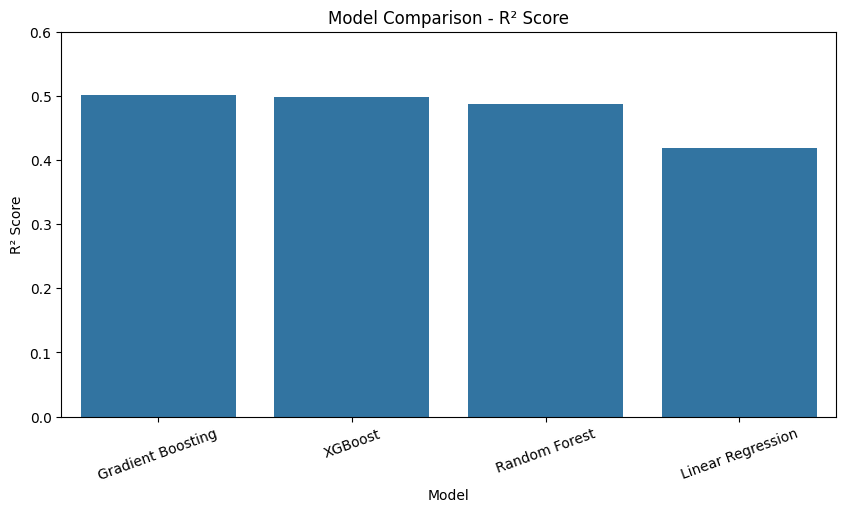

In [37]:
# Compare R² scores

plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="R2"
)

plt.title("Model Comparison - R² Score")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.xticks(rotation=20)
plt.ylim(0, 0.6)
plt.show()

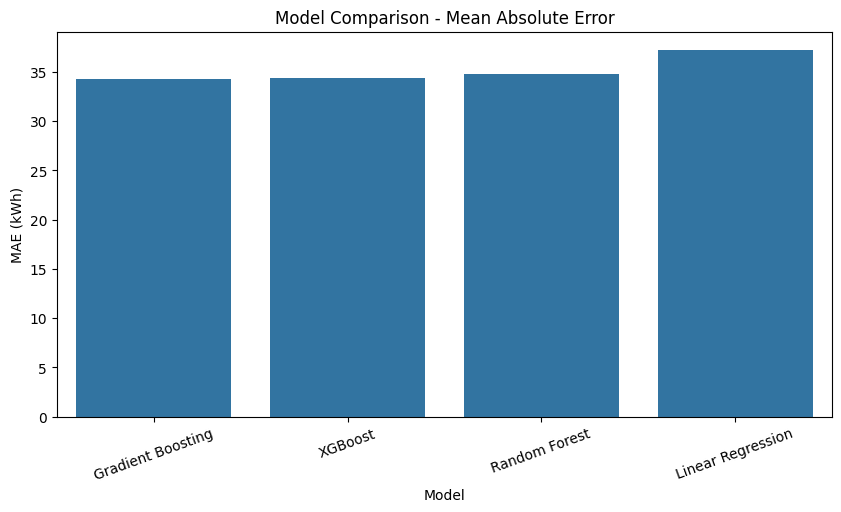

In [38]:
# Compare MAE

plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="MAE"
)

plt.title("Model Comparison - Mean Absolute Error")
plt.xlabel("Model")
plt.ylabel("MAE (kWh)")
plt.xticks(rotation=20)
plt.show()

## Actual vs Predicted Demand

The actual and predicted values of the best-performing model are
compared to visually evaluate prediction accuracy.

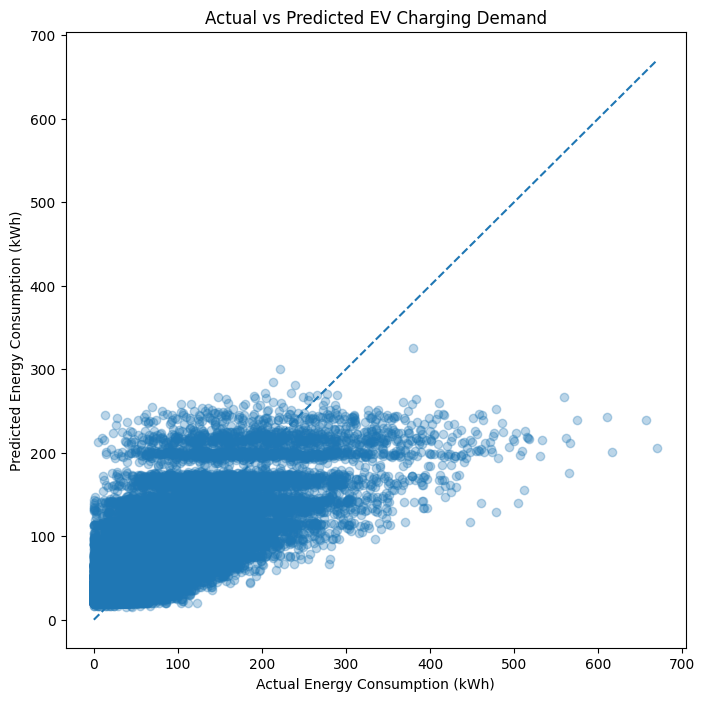

In [39]:
# Actual vs predicted values for Gradient Boosting

plt.figure(figsize=(8, 8))

plt.scatter(
    y_val,
    y_val_pred_gb,
    alpha=0.3
)

# Perfect prediction line
min_value = min(y_val.min(), y_val_pred_gb.min())
max_value = max(y_val.max(), y_val_pred_gb.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted EV Charging Demand")
plt.xlabel("Actual Energy Consumption (kWh)")
plt.ylabel("Predicted Energy Consumption (kWh)")
plt.show()

## Feature Importance

Feature importance is used to identify which variables have the greatest
influence on the Gradient Boosting model's predictions.

This helps us understand the major factors affecting EV charging demand.

In [40]:
# Extract the trained Gradient Boosting model

gb_model = gradient_boosting_model.named_steps["model"]

# Get the preprocessing step
gb_preprocessor = gradient_boosting_model.named_steps["preprocessor"]

# Get feature names after preprocessing
feature_names = gb_preprocessor.get_feature_names_out()

# Get feature importance
importance = gb_model.feature_importances_

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
17,numerical__hour,0.577365
16,numerical__charger_count,0.212450
31,numerical__hour_cos,0.090291
29,numerical__rolling_7d_mean,0.037673
30,numerical__hour_sin,0.028348
28,numerical__rolling_24h_mean,0.007456
18,numerical__day_of_week,0.006314
27,numerical__previous_week_demand,0.004932
32,numerical__day_sin,0.004657
20,numerical__is_weekend,0.003776


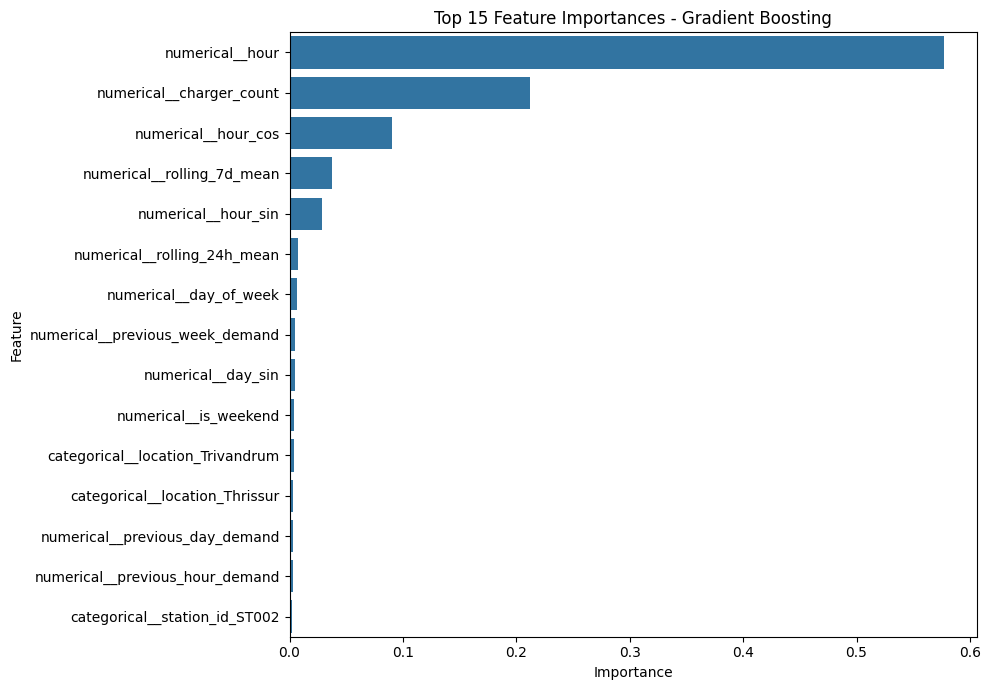

In [41]:
# Top 15 important features

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances - Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## Final Model Evaluation

Gradient Boosting achieved the best validation performance.

The model is now evaluated on the test dataset, which was not used
during model selection.

In [42]:
# Generate predictions on the test set

y_test_pred = gradient_boosting_model.predict(X_test)

print("Test predictions generated successfully!")

Test predictions generated successfully!


In [43]:
# Final test performance

mae_test = mean_absolute_error(y_test, y_test_pred)

rmse_test = np.sqrt(
    mean_squared_error(y_test, y_test_pred)
)

r2_test = r2_score(
    y_test,
    y_test_pred
)

print("Gradient Boosting - Final Test Performance")
print("-------------------------------------------")
print(f"MAE  : {mae_test:.2f} kWh")
print(f"RMSE : {rmse_test:.2f} kWh")
print(f"R²   : {r2_test:.4f}")

Gradient Boosting - Final Test Performance
-------------------------------------------
MAE  : 34.04 kWh
RMSE : 47.53 kWh
R²   : 0.4910


## Final Actual vs Predicted Analysis

The final Gradient Boosting model is evaluated by comparing actual
energy consumption with predicted energy consumption on the unseen
test dataset.

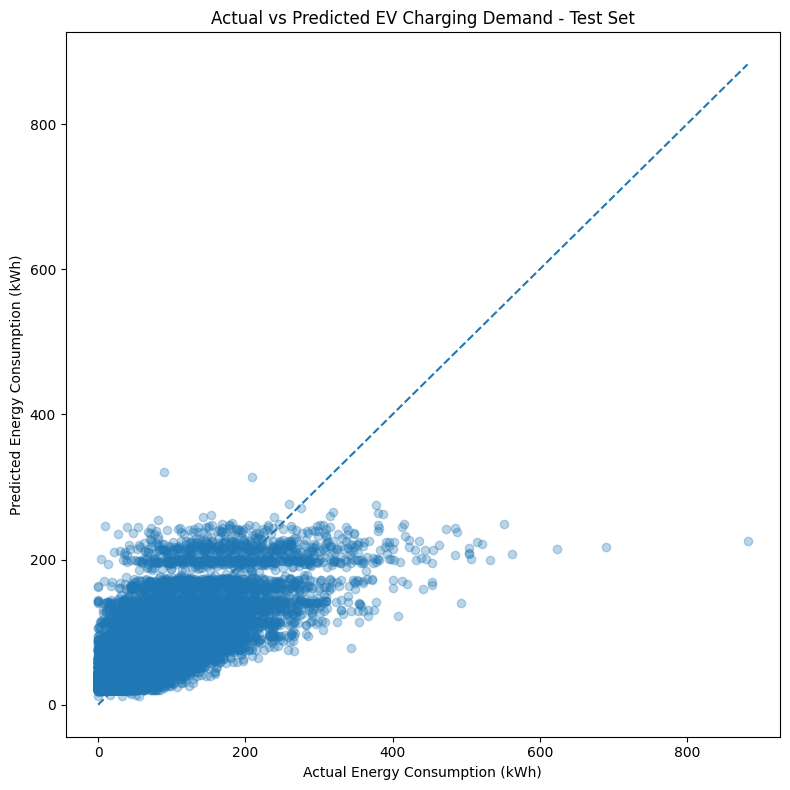

In [44]:
# Actual vs Predicted - Test Set

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.3
)

# Perfect prediction line
min_value = min(y_test.min(), y_test_pred.min())
max_value = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted EV Charging Demand - Test Set")
plt.xlabel("Actual Energy Consumption (kWh)")
plt.ylabel("Predicted Energy Consumption (kWh)")

plt.tight_layout()
plt.show()

## Save the Final Model

The trained Gradient Boosting model is saved using Joblib so that it
can be reused for future predictions and deployment.

In [45]:
import joblib
import os

# Create models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the trained model
model_path = "../models/gradient_boosting_ev_demand_model.pkl"

joblib.dump(
    gradient_boosting_model,
    model_path
)

print("Model saved successfully!")
print("Saved to:", model_path)

Model saved successfully!
Saved to: ../models/gradient_boosting_ev_demand_model.pkl


# Project Conclusion

## Objective

The objective of this project was to predict hourly EV charging
electricity demand using historical demand, station characteristics,
calendar information, and weather conditions.

## Models Evaluated

Four traditional machine learning regression models were evaluated:

1. Linear Regression
2. Random Forest Regressor
3. Gradient Boosting Regressor
4. XGBoost Regressor

## Best Model

Gradient Boosting Regressor achieved the best validation performance.

### Final Test Performance

- MAE: **34.04 kWh**
- RMSE: **47.53 kWh**
- R² Score: **0.4910**

The model explains approximately 49.1% of the variation in unseen
EV charging demand.

## Key Findings

- Charging demand varies significantly throughout the day.
- Evening hours show higher charging demand.
- Weekend demand differs from weekday demand.
- Stations with more chargers generally have higher energy demand.
- Historical demand features are important predictors.
- Gradient Boosting performed better than Linear Regression,
  Random Forest, and XGBoost on the validation dataset.

## Business Value

The prediction system can help EV charging station operators:

- Plan charger availability
- Anticipate high-demand periods
- Improve electricity-load planning
- Support operational decision-making
- Reduce unexpected peak-demand situations

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- XGBoost
- Joblib

## Machine Learning Type

Supervised Learning — Regression


## Final Model Comparison

| Model | MAE (kWh) | RMSE (kWh) | R² |
|---|---:|---:|---:|
| Linear Regression | 37.23 | 51.81 | 0.4180 |
| Random Forest | 34.78 | 48.66 | 0.4866 |
| Gradient Boosting | 34.31 | 47.99 | 0.5007 |
| XGBoost | 34.37 | 48.12 | 0.4980 |

### Best Model

**Gradient Boosting Regressor**

Validation R²: **0.5007**

Final Test R²: **0.4910**

Final Test MAE: **34.04 kWh**

Final Test RMSE: **47.53 kWh**